In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, mean_squared_error, mean_absolute_error, r2_score)

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
print("numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)

numpy 2.5.1 | pandas 3.0.5 | sklearn 1.9.0


In [2]:
def evaluate_classification_metrics(model, X_valid, y_valid, title="Classification Report"):
    """
    Universal function for evaluating models (including regressors)
    with classification metrics.
    """
    # 1. Make predictions
    predictions = model.predict(X_valid)

    # 2. If the model returns fractional numbers (regression), round them
    predictions_rounded = np.round(predictions)

    # 3. Compute the standard metrics
    # zero_division=0 prevents warnings if the model never predicted a given class
    acc = accuracy_score(y_valid, predictions_rounded)
    prec = precision_score(y_valid, predictions_rounded, average='macro', zero_division=0)
    rec = recall_score(y_valid, predictions_rounded, average='macro', zero_division=0)
    f1 = f1_score(y_valid, predictions_rounded, average='macro', zero_division=0)

    print(f"--- {title} ---")
    print(f"Accuracy:  {acc:.4f} (Share of exact hits)")
    print(f"Precision: {prec:.4f} (Macro)")
    print(f"Recall:    {rec:.4f} (Macro)")
    print(f"F1-Score:  {f1:.4f} (Macro)\n")

    # 4. Classification of the error size (our own metric)
    exact_matches = np.sum(predictions_rounded == y_valid)
    off_by_one = np.sum(np.abs(predictions_rounded - y_valid) == 1)
    total = len(y_valid)

    print("--- Error distribution ---")
    print(f"Exact match:            {exact_matches/total*100:.2f}%")
    print(f"Off by 1 point:         {off_by_one/total*100:.2f}%")
    print(f"Gross error (>1 point): {(total - exact_matches - off_by_one)/total*100:.2f}%\n")

    # 5. Confusion matrix visualisation
    cm = confusion_matrix(y_valid, predictions_rounded)

    # Get the unique classes (scores) that are actually present in the validation set
    classes = np.unique(np.concatenate([y_valid, predictions_rounded]))

    plt.figure(figsize=(8, 6))
    # annot=True shows the numbers, cmap='Blues' sets the blue colour map
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes)

    plt.title(f'Confusion Matrix: {title}')
    plt.ylabel('Actual score')
    plt.xlabel('Predicted score')
    plt.tight_layout()
    plt.show()

In [3]:
# The cleaned dataset is produced by wine_quality_eda.ipynb: duplicate rows are already removed
# (so identical rows cannot end up in both train and test) and there are no missing values.
CLEAN_PATH = "dataset/wine_clean.csv"

raw = pd.read_csv(CLEAN_PATH)

# Sanity checks: the experiment relies on these properties of the cleaned data
assert raw.isna().sum().sum() == 0, "unexpected missing values"
assert not raw.duplicated().any(), "unexpected duplicate rows"

# wine_type is stored as text in the CSV; the models need a number: 0 = red, 1 = white.
# quality_category (low / medium / high) is not used in this notebook, so it is dropped.
df = (raw.assign(wine_type=raw["wine_type"].map({"red": 0, "white": 1}))
         .drop(columns="quality_category"))
assert df["wine_type"].notna().all(), "unknown wine_type value"

print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Combined dataset:", df.shape)
display(df["wine_type"].map({0: "red", 1: "white"}).value_counts().rename("rows").to_frame())

Missing values: 0
Duplicate rows: 0
Combined dataset: (5320, 13)


,rows
wine_type,
white,3961
red,1359


wine_type,red,white
quality,,
3,10,20
4,53,153
5,577,1175
6,535,1788
7,167,689
8,17,131
9,0,5


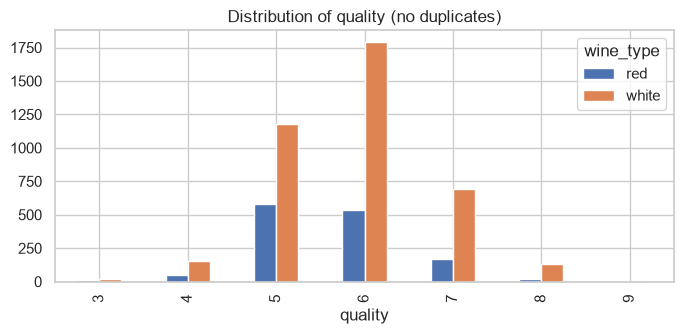

In [4]:
# Target distribution after cleaning
dist = pd.crosstab(df["quality"], df["wine_type"].map({0: "red", 1: "white"}))
display(dist)
dist.plot(kind="bar", figsize=(7, 3.5), title="Distribution of quality (no duplicates)")
plt.tight_layout(); plt.show()

In [5]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
strat = df["wine_type"].astype(str) + "_" + df["quality"].astype(str)
folds = list(skf.split(df, strat))

def make_svm():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVR(kernel="rbf"))
    ])

In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error
import numpy as np

def evaluate_svm_valid(X_train, X_valid, y_train, y_valid, scenario_name, use_wine_type=False):
    # Вибір препроцесора залежно від наявності текстової колонки wine_type
    if use_wine_type:
        numeric_features = X_train.select_dtypes(include=['number']).columns
        categorical_features = ['wine_type']
        
        preprocessor = ColumnTransformer(
            transformers=[
                ('num', StandardScaler(), numeric_features),
                ('cat', OneHotEncoder(drop='first'), categorical_features)
            ])
    else:
        preprocessor = StandardScaler()
        
    # Створення конвеєра: підготовка даних + SVM
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', SVR(kernel='rbf', C=1.0, epsilon=0.1))
    ])
    
    # Навчання на тренувальній вибірці
    pipeline.fit(X_train, y_train)
    
    # Прогнозування та оцінка на валідаційній вибірці
    preds = pipeline.predict(X_valid)
    rmse = np.sqrt(mean_squared_error(y_valid, preds))
    print(f"SVM Validation RMSE ({scenario_name}): {rmse:.4f}")
    
    return pipeline

print("--- Результати SVM на валідаційній вибірці ---")

# 1. Тільки червоне вино
svm_red = evaluate_svm_valid(
    X_train_red, X_valid_red, y_train_red, y_valid_red, "Тільки червоне"
)

# 2. Тільки біле вино
svm_white = evaluate_svm_valid(
    X_train_white, X_valid_white, y_train_white, y_valid_white, "Тільки біле"
)

# 3. Об'єднаний датасет БЕЗ типу вина
# Видаляємо колонку wine_type з уже створених об'єднаних вибірок
X_train_comb_no_type = X_train_comb.drop(columns=['wine_type'])
X_valid_comb_no_type = X_valid_comb.drop(columns=['wine_type'])

svm_comb_no_type = evaluate_svm_valid(
    X_train_comb_no_type, X_valid_comb_no_type, y_train_comb, y_valid_comb, "Об'єднаний (без типу)"
)

# 4. Об'єднаний датасет З типом вина
svm_comb_with_type = evaluate_svm_valid(
    X_train_comb, X_valid_comb, y_train_comb, y_valid_comb, "Об'єднаний (з типом)", use_wine_type=True
)

--- Результати SVM на валідаційній вибірці ---


NameError: name 'X_train_red' is not defined